# Midterm Question 8 Coding Answers

## A) Data Exploration and Pre-Processing

### i) Import the student-mat.csv dataset as a pandas DataFrame

In [38]:
import pandas as pd
import numpy as np

my_df = pd.read_csv("student-mat.csv", sep = ";")
print(my_df)

    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
390     MS   M   20       U     LE3       A     2     2  services  services   
391     MS   M   17       U     LE3       T     3     1  services  services   
392     MS   M   21       R     GT3       T     1     1     other     other   
393     MS   M   18       R     LE3       T     3     2  services     other   
394     MS   M   19       U     LE3       T     1     1     other   at_home   

     ... famrel freetime  goout  Dalc  Walc health 

### ii) Select the following features: age, studytime, schoolsup, goout, Dalc, Walc, health, absences, G3 (target/dependent variable). Encode the binary variable(schoolsup) values as 0s (no) and 1s (yes). Combine Dalc and Walc into one variable alc by taking averge, then remove Dalc and Walc. Display the first five rows of the pre-processed dataset.

In [39]:
#Selecting features
print(my_df.columns.tolist())
my_df = my_df.drop(columns = ["sex","address","famsize","Pstatus","Medu","Fedu","Mjob","Fjob","romantic","famrel","freetime","G1","G2",
                             "school","reason","guardian","traveltime","failures","famsup","paid","activities","nursery","higher",
                             "internet"])

#Encoding schoolsup variable
my_df["schoolsup"] = my_df["schoolsup"].map({"no" : 0, "yes" : 1})

#Combining Dalc and Walc into alc
my_df["alc"] = (my_df["Dalc"] + my_df["Walc"]) / 2
my_df = my_df.drop(columns = ["Dalc","Walc"])

#Printing the results of the manipulated data frame
print("\n")
print(my_df.head())

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


   age  studytime  schoolsup  goout  health  absences  G3  alc
0   18          2          1      4       3         6   6  1.0
1   17          2          0      3       3         4   6  1.0
2   15          2          1      2       3        10  10  2.5
3   15          3          0      2       5         2  15  1.0
4   16          2          0      2       5         4  10  1.5


### iii) Find the number of outliers for each independent variable using the IQR method

In [40]:
ind_vars = my_df.drop(columns = "G3")
count_of_outliers = {}

for i in ind_vars:
    quartile_one = ind_vars[i].quantile(0.25)
    quartile_three = ind_vars[i].quantile(0.75)
    IQR = quartile_three - quartile_one

    lower_boundary = quartile_one - (1.5 * IQR)
    upper_boundary = quartile_three + (1.5 * IQR)

    my_outliers = ind_vars[(ind_vars[i] < lower_boundary) | (ind_vars[i] > upper_boundary)]
    count_of_outliers[i] = len(my_outliers)
    
for o,c in count_of_outliers.items():
    print(f"{o} = {c} outliers")

age = 1 outliers
studytime = 27 outliers
schoolsup = 51 outliers
goout = 0 outliers
health = 0 outliers
absences = 15 outliers
alc = 9 outliers


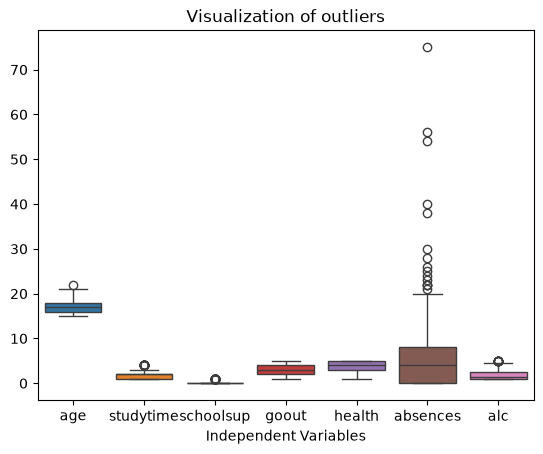

In [41]:
import seaborn as sns
#PLotting the outliers using boxplot
sns.boxplot(data=my_df.drop(columns = "G3"))
plt.title("Visualization of outliers")
plt.xlabel("Independent Variables")
plt.show()

### iv) Standardize and run PCA on the dataset. Create a scatterplot of PC1 vs PC2, coloring the dots by their final grade G3. Inspect the component loadings and determine which features contribute the most to PC1 and PC2.

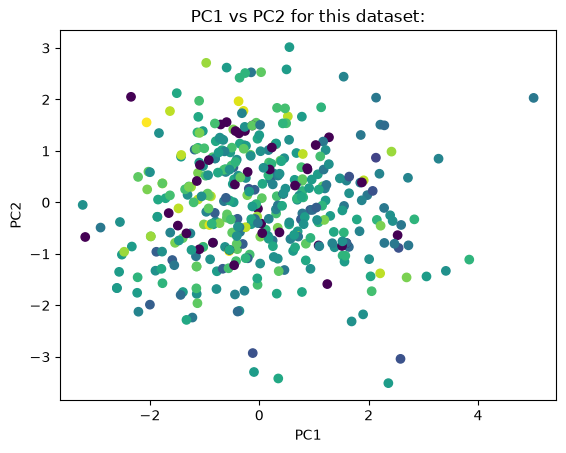

In [42]:
#Importing necessary libraries
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#Splitting features and target variable
x = my_df.drop(columns = "G3")
y = my_df["G3"]

#Creating and initializing the scaler for PCA
my_scaler = StandardScaler()
x_scaled = my_scaler.fit_transform(x)

#Creating and running a PCA on the dataset
my_pca = PCA(n_components = 2)
p_comp = my_pca.fit_transform(x_scaled)

#Storing the PCA values
my_pca_dataf = pd.DataFrame(data = p_comp, columns = ["PC1","PC2"])
my_pca_dataf["G3"] = y.values

#Creating the scatterplot to plot the PC1 vs PC2
my_scatter = plt.scatter(my_pca_dataf["PC1"],my_pca_dataf["PC2"],c = my_pca_dataf["G3"])
plt.title("PC1 vs PC2 for this dataset:")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


In [43]:
#Creating a dataframe of components of the features
components = pd.DataFrame(my_pca.components_.T,columns = ["PC1","PC2"], index = x.columns)
print(components)

                PC1       PC2
age        0.381940  0.589260
studytime -0.329734  0.385671
schoolsup -0.248184 -0.464202
goout      0.493755 -0.139613
health     0.080545 -0.400925
absences   0.280106  0.182798
alc        0.595871 -0.273677


In [44]:
#Determining which features contribute the most to PC1 and PC2
print("Most impactful features of PC1:\n")
print(components["PC1"].abs().sort_values(ascending = False))
print("\n")
print("Most impactful features of PC2:\n")
print(components["PC2"].abs().sort_values(ascending = False))


Most impactful features of PC1:

alc          0.595871
goout        0.493755
age          0.381940
studytime    0.329734
absences     0.280106
schoolsup    0.248184
health       0.080545
Name: PC1, dtype: float64


Most impactful features of PC2:

age          0.589260
schoolsup    0.464202
health       0.400925
studytime    0.385671
alc          0.273677
absences     0.182798
goout        0.139613
Name: PC2, dtype: float64


## B) Linear Regression

### i) Split data into training set and testing set with an 80:20 ratio. Use random seed 552 for reproducibility.

In [45]:
from sklearn.model_selection import train_test_split
x = my_df.drop(columns = "G3")
y = my_df["G3"]

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2, random_state = 552)

new_scaler = StandardScaler()
x_train_scaled = new_scaler.fit_transform(x_train)
x_test_scaled = new_scaler.transform(x_test)


### ii) Build three models using the training set: A. Linear Regression Model, B. Linear Regression Model with Ridge Regularization, and C. Linear Regression Model with Lasso Regularization. Set α=0.1

In [46]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

#Creating/training a normal linear regression model
normal_lin_reg_model = LinearRegression()
normal_lin_reg_model.fit(x_train_scaled,y_train)

#Creating/training a Linear regression model with Ridge Regularization
ridge_lin_reg_model = Ridge(alpha = 0.1)
ridge_lin_reg_model.fit(x_train_scaled,y_train)

#Creating/training a linear regression model with Lasso Regularization
lasso_lin_reg_model = Lasso(alpha = 0.1)
lasso_lin_reg_model.fit(x_train_scaled,y_train)


,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


### iii) Test all three models on the test set. Find out the best performing model with repsect to each of the metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

In [47]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Getting the prediction values to use for testing from each model
y_pred_lin_normal = normal_lin_reg_model.predict(x_test_scaled)
y_pred_ridge_lin = ridge_lin_reg_model.predict(x_test_scaled)
y_pred_lasso_lin = lasso_lin_reg_model.predict(x_test_scaled)

#Creating a dictionary to compute and print the stats needed of each model:
my_results = {
    "Linear Regression" : {"MAE" : mean_absolute_error(y_test,y_pred_lin_normal), "RMSE":np.sqrt(mean_squared_error(y_test,y_pred_lin_normal)), 
                            "R2" : r2_score(y_test,y_pred_lin_normal),
                            },
    "Ridge at (Alpha = 0.1)" : {"MAE" : mean_absolute_error(y_test,y_pred_ridge_lin), "RMSE":np.sqrt(mean_squared_error(y_test,y_pred_ridge_lin)),
                                   "R2" : r2_score(y_test,y_pred_lin_normal),
                                 },
    "Lasso at (Alpha = 0.1)" : {"MAE" : mean_absolute_error(y_test,y_pred_ridge_lin), "RMSE":np.sqrt(mean_squared_error(y_test,y_pred_ridge_lin)),
                                   "R2" : r2_score(y_test,y_pred_lin_normal),
                                 },
}

#Printing the results of the functions
results_df = pd.DataFrame(my_results).T
print(results_df.round(6))



                             MAE      RMSE        R2
Linear Regression       3.418009  4.755812  0.028177
Ridge at (Alpha = 0.1)  3.418064  4.755860  0.028177
Lasso at (Alpha = 0.1)  3.418064  4.755860  0.028177


In [48]:
#Figuring out the best model for each of the metrics
best_model_mae = results_df["MAE"].idxmin()
best_model_rmse = results_df["RMSE"].idxmin()
best_model_r2 = results_df["R2"].idxmax()

#Printing the answers
print("The best model using the MAE value: ",best_model_mae)
print("The best model using the RMSE value: ", best_model_rmse)
print("The best model using the R2 value: ",best_model_r2)

The best model using the MAE value:  Linear Regression
The best model using the RMSE value:  Linear Regression
The best model using the R2 value:  Linear Regression


### iv) How do you interpret R² values from the three models?

Based on the R^2 values given to me in the table, i can interpret that all three of the models are not a good fit for this dataset. This is because of how close to 0 the R^2 value is for each of the models. Also because of having a low alpha of 0.1, both the ridge model and lasso model are equal to the r2 score of the linear regression mode, showing that there is not much difference between the three. 

### v) Print coefficients of independent variables from the three models in one table.

In [49]:
coefficients = pd.DataFrame({
    "Linear Regression" : normal_lin_reg_model.coef_,
    "Ridge (Alpha = 0.1)": ridge_lin_reg_model.coef_,
    "Lasso (Alpha = 0.1)" : lasso_lin_reg_model.coef_
}, index = x_train.columns
                           )
print("Coefficients Table:\n")
print(coefficients.round(4))

Coefficients Table:

           Linear Regression  Ridge (Alpha = 0.1)  Lasso (Alpha = 0.1)
age                  -0.7853              -0.7850              -0.6309
studytime             0.4491               0.4490               0.3513
schoolsup            -0.7178              -0.7175              -0.5701
goout                -0.5701              -0.5699              -0.4777
health               -0.2458              -0.2457              -0.1419
absences              0.1978               0.1977               0.0708
alc                   0.0363               0.0361              -0.0000


### vi) What’s the relationship between each independent variable and the dependent variable?

- The relationship between the independent variabe of **age** and the dependent variable of **G3**: **A small negative relationship**.
- The relationship between the independent variable of **studytime** and the dependent variable of **G3**: **A small positive relationship.**
- The relationship between the independent variable of **schoolsup** and the dependent variable of **G3**: **A small negative relationship.**
- The relationship between the independent variable of **goout** and the dependent variable of **G3**: **A negative relationship.**
- The relationship between the independent variable of **health** and the dependent variable of **G3**: **A negative relationship.**
- The relationship between the independent variable of **absences** and the dependent variable of **G3**: **A small positive relationship.**
- The relationship between the independent variable of **alc** and the dependent variable of **G3**: **A small positive relationship.**

### vii) How do the regularization methods differ? What can you conclude about the dataset and features given the results?

The two regularization methods implement in this problem do not differ because their mae, rmse, and r2 scores are exactly the same. However they do differ from a normal linear regression model in terms of the coefficients of each independent variable when compared to G3.  From the features and dataset given in this problem I can conclude that the best machine learning model to use for this dataset is a normal linear regression model with no regularizer. I am also able to conclude that the independent variable which has to most positive impact on G3 is **studytime** and the independent variable with the most negative impact on G3 is **age**, which is based on the results of all three models.

### vii) If the regularization strength (α) is increased, what would happen to performance metrics?

If the value of alpha was increased, the performance metrics for training mse and rmse would increase while, the training r2 score would worsen.

### ix) What are some feature engineering methods you would suggest to improve model performance?

The first suggestion I would make to improve model performance would be to add more features to the dataset. Another suggestion would be to increase the value of alpha for the models using regularizers. 